# PROYECTO INDIVIDUAL: GESTIÓN HOSPITALARIA
### Análisis de costos, cobertura y reinternaciones de un hospital

**Nuestro rol.** En este proyecto nos situamos en el rol de **Analistas de Datos**, convocados para estudiar la información histórica de un hospital y transformarla en respuestas concretas para su dirección.

**El contexto.** La dirección del **Massachusetts General Hospital** percibe que sus costos vienen en aumento con el paso de los años, pero no tiene claro hacia dónde se está yendo el presupuesto: qué tipo de consultas son las más costosas, cuánto de esos costos cubren los seguros y si hay pacientes que vuelven una y otra vez al hospital. Sin esa información, es difícil decidir dónde actuar.

**La tarea.** Analizar las consultas, los costos, la cobertura de los seguros y las internaciones de los pacientes, verificar una serie de hipótesis planteadas junto a la dirección y proponer recomendaciones basadas en los datos.

**Las preguntas de negocio (hipótesis).** Una *hipótesis* es una suposición que los datos pueden confirmar o rechazar:

- **H1:** la actividad y los costos del hospital cambiaron mucho entre años.
- **H2:** las internaciones son pocas, pero concentran la mayor parte de los costos.
- **H3:** una parte grande de las consultas no tiene cobertura, lo que aumenta el riesgo de no cobrar.
- **H4:** algunos pacientes vuelven a internarse con mucha frecuencia.

**Los datos.** Trabajamos con los registros del hospital entre 2011 y febrero de 2022: pacientes, consultas e internaciones, procedimientos (estudios y tratamientos) y aseguradoras. Los datos son **sintéticos** (realistas, pero generados por computadora) y fueron publicados por **Maven Analytics** con licencia de dominio público.

## 1. Carga de los datos

Para empezar, cargamos las cinco tablas del hospital tal como se descargaron, desde la carpeta `data/raw` (datos originales, que nunca se modifican). Leemos los códigos postales (`ZIP`) como texto: si se leen como números, un código como 02114 se convierte en 2114 y pierde el cero inicial.

A continuación importamos las librerías (pandas para trabajar con tablas y Matplotlib para los gráficos), cargamos las tablas y mostramos su tamaño (filas, columnas).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

ruta = "../data/raw/"

patients = pd.read_csv(ruta + "patients.csv", dtype={"ZIP": str})
encounters = pd.read_csv(ruta + "encounters.csv")
procedures = pd.read_csv(ruta + "procedures.csv")
payers = pd.read_csv(ruta + "payers.csv", dtype={"ZIP": str})
organizations = pd.read_csv(ruta + "organizations.csv")

print("patients:", patients.shape)
print("encounters:", encounters.shape)
print("procedures:", procedures.shape)
print("payers:", payers.shape)
print("organizations:", organizations.shape)

patients: (974, 20)
encounters: (27891, 14)
procedures: (47701, 9)
payers: (10, 7)
organizations: (1, 8)


### Qué encontramos

Tenemos **974 pacientes**, **27.891 consultas e internaciones** (la tabla central, `encounters`), **47.701 procedimientos**, **10 aseguradoras** y **1 hospital**. Todas las consultas pertenecen al mismo hospital, por lo que la tabla `organizations` no aporta comparaciones.

## 2. Primer vistazo a las tablas

Antes de sacar conclusiones, necesitamos saber si los datos están completos y bien cargados. Un dato vacío (*nulo*) puede ser un error o puede tener sentido; y un tipo de dato incorrecto (por ejemplo, una fecha guardada como texto) impide hacer cálculos.

A continuación, para cada tabla, mostramos sus columnas con su tipo de dato (`info()`) y la cantidad de valores vacíos por columna.

In [2]:
tablas = {
    "patients": patients,
    "encounters": encounters,
    "procedures": procedures,
    "payers": payers,
    "organizations": organizations,
}

for nombre, tabla in tablas.items():
    print("=" * 20, nombre, "=" * 20)
    tabla.info()
    print("\nValores vacíos por columna:")
    print(tabla.isna().sum())
    print()

==================== patients ====================
<class 'pandas.DataFrame'>
RangeIndex: 974 entries, 0 to 973
Data columns (total 20 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Id          974 non-null    str    
 1   BIRTHDATE   974 non-null    str    
 2   DEATHDATE   154 non-null    str    
 3   PREFIX      974 non-null    str    
 4   FIRST       974 non-null    str    
 5   LAST        974 non-null    str    
 6   SUFFIX      21 non-null     str    
 7   MAIDEN      386 non-null    str    
 8   MARITAL     973 non-null    str    
 9   RACE        974 non-null    str    
 10  ETHNICITY   974 non-null    str    
 11  GENDER      974 non-null    str    
 12  BIRTHPLACE  974 non-null    str    
 13  ADDRESS     974 non-null    str    
 14  CITY        974 non-null    str    
 15  STATE       974 non-null    str    
 16  COUNTY      974 non-null    str    
 17  ZIP         832 non-null    str    
 18  LAT         974 non-null    fl

Además, revisamos si hay filas repetidas (*duplicados*) en las tablas de procedimientos y aseguradoras. A continuación contamos las filas duplicadas de cada una.

In [3]:
print("Filas duplicadas en procedures:", procedures.duplicated().sum())
print("Filas duplicadas en payers:", payers.duplicated().sum())

Filas duplicadas en procedures: 0
Filas duplicadas en payers: 0


In [4]:
payers[["NAME"]]

,NAME
0,Dual Eligible
1,Medicare
2,Medicaid
3,Humana
4,Blue Cross Blue Shield
5,UnitedHealthcare
6,Aetna
7,Cigna Health
8,Anthem
9,NO_INSURANCE


### Qué encontramos

- **La mayoría de los vacíos tienen sentido y no son errores:**
  - `DEATHDATE` (fecha de fallecimiento) está vacía en 820 pacientes: son los pacientes que siguen vivos.
  - `REASONCODE` y `REASONDESCRIPTION` (motivo de la consulta) están vacíos en 19.541 consultas y 36.945 procedimientos: no todas las atenciones registran un motivo, por ejemplo los controles de rutina.
  - `SUFFIX` y `MAIDEN` (sufijo y apellido de soltera) son datos personales opcionales, que además no usamos en el análisis.
  - En `payers`, la aseguradora "NO_INSURANCE" no tiene dirección ni teléfono, porque no es una empresa real.
- **Vacíos a tener en cuenta:** 142 pacientes no tienen código postal y 1 no tiene estado civil.
- **Tipos de datos a corregir:** las fechas (`BIRTHDATE`, `DEATHDATE`, `START`, `STOP`) están guardadas como texto y hay que convertirlas a fecha. El código postal de `organizations` quedó como número; como no lo usamos, no lo corregimos.
- **No hay filas duplicadas** en procedimientos ni en aseguradoras.
- **Las aseguradoras incluyen "NO_INSURANCE"**, que no es una aseguradora: identifica las consultas de pacientes **sin seguro**. Esto será clave para analizar la cobertura (H3).

## 3. Perfil de los pacientes

Conocer a quién atiende el hospital ayuda a entender sus costos: una población mayor suele necesitar más atención. Para calcular la edad, primero convertimos las fechas de nacimiento y fallecimiento a formato fecha.

Como los datos terminan en 2022, calculamos la edad hasta una **fecha de referencia**: la última fecha de alta registrada en las consultas. Para los pacientes fallecidos, en cambio, usamos la fecha de fallecimiento (con `fillna`, que completa los vacíos: si el paciente no falleció, usamos la fecha de referencia).

A continuación convertimos las fechas, definimos la fecha de referencia y calculamos la edad de cada paciente.

In [5]:
patients["BIRTHDATE"] = pd.to_datetime(patients["BIRTHDATE"])
patients["DEATHDATE"] = pd.to_datetime(patients["DEATHDATE"])

fecha_referencia = pd.to_datetime(encounters["STOP"]).max().tz_localize(None)
print("Fecha de referencia:", fecha_referencia)

fecha_fin = patients["DEATHDATE"].fillna(fecha_referencia)

patients["EDAD"] = (fecha_fin - patients["BIRTHDATE"]).dt.days // 365
patients["EDAD"].describe()

Fecha de referencia: 2022-02-05 20:42:36


count    974.000000
mean      68.600616
std       19.999734
min       26.000000
25%       51.000000
50%       70.500000
75%       86.000000
max       99.000000
Name: EDAD, dtype: float64

Para ver cómo se distribuyen las edades, a continuación graficamos un *histograma*: cada barra muestra cuántos pacientes hay en un rango de edad.

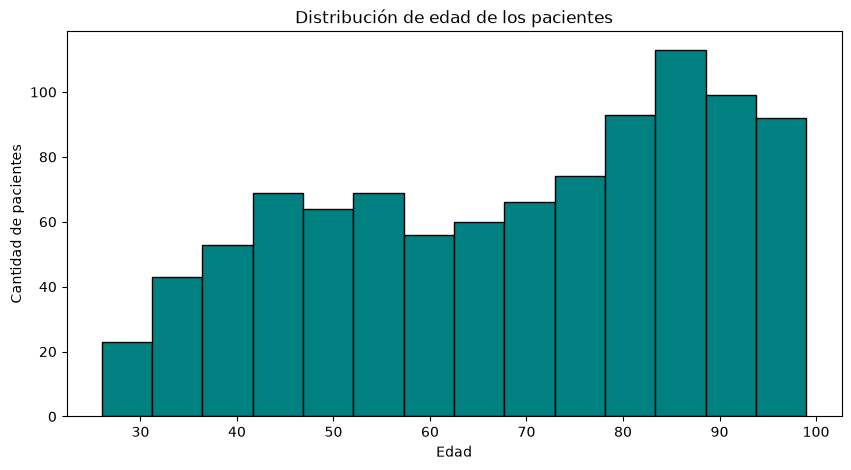

In [6]:
plt.figure(figsize=(10, 5))
plt.hist(patients["EDAD"], bins=14, edgecolor="black", color="teal")
plt.title("Distribución de edad de los pacientes")
plt.xlabel("Edad")
plt.ylabel("Cantidad de pacientes")
plt.show()

A continuación agrupamos a los pacientes en rangos de edad con `pd.cut` y contamos cuántos hay en cada uno.

In [7]:
patients["RANGO_EDAD"] = pd.cut(
    patients["EDAD"],
    bins=[0, 40, 60, 80, 120],
    labels=["Menos de 40", "40 a 59", "60 a 79", "80 o más"]
)

patients["RANGO_EDAD"].value_counts().sort_index()

RANGO_EDAD
Menos de 40    108
40 a 59        241
60 a 79        262
80 o más       363
Name: count, dtype: int64

Por último, a continuación vemos el género, el estado civil, el condado donde viven y cuántos pacientes fallecieron.

In [8]:
print("Género:")
print(patients["GENDER"].value_counts())

print("\nEstado civil (M = casado/a, S = soltero/a):")
print(patients["MARITAL"].value_counts())

print("\nCondado de residencia (%):")
print(round(patients["COUNTY"].value_counts(normalize=True) * 100, 1))

fallecidos = patients["DEATHDATE"].notna()
print("\nPacientes fallecidos:", fallecidos.sum(), "-", round(fallecidos.mean() * 100, 1), "%")

Género:
GENDER
M    494
F    480
Name: count, dtype: int64

Estado civil (M = casado/a, S = soltero/a):
MARITAL
M    784
S    189
Name: count, dtype: int64

Condado de residencia (%):
COUNTY
Suffolk County      66.1
Norfolk County      15.9
Middlesex County    12.8
Plymouth County      5.0
Essex County         0.1
Name: proportion, dtype: float64

Pacientes fallecidos: 154 - 15.8 %


### Qué encontramos

El hospital atiende sobre todo a **personas mayores y de la zona**:

- La **edad promedio es de 68,6 años** y la **mediana, de 70,5 años** (la mediana es el valor del medio: la mitad de los pacientes tiene menos de 70,5 años y la otra mitad, más). El paciente más joven tiene 26 años: **no hay niños ni adultos jóvenes** en los datos.
- El **37%** de los pacientes está en el grupo de 80 años o más.
- El género es parejo: **494 hombres y 480 mujeres**.
- El **66% vive en el condado de Suffolk**, donde está el hospital.
- **154 pacientes fallecieron (16%)**.

## 4. Las consultas

Las consultas son el corazón de la actividad y de los costos del hospital. Primero convertimos las fechas de inicio (`START`) y fin (`STOP`) a formato fecha, quitando la zona horaria para poder compararlas con otras fechas.

A continuación convertimos las fechas y creamos tres columnas nuevas: el **año** de la consulta, su **duración en horas** y el monto que **paga el paciente** de su bolsillo (el costo total menos lo que cubre el seguro).

In [9]:
encounters["START"] = pd.to_datetime(encounters["START"]).dt.tz_localize(None)
encounters["STOP"] = pd.to_datetime(encounters["STOP"]).dt.tz_localize(None)

encounters["AÑO"] = encounters["START"].dt.year
encounters["DURACION_HORAS"] = (encounters["STOP"] - encounters["START"]).dt.total_seconds() / 3600
encounters["PAGA_PACIENTE"] = encounters["TOTAL_CLAIM_COST"] - encounters["PAYER_COVERAGE"]

encounters[["AÑO", "DURACION_HORAS", "TOTAL_CLAIM_COST", "PAYER_COVERAGE", "PAGA_PACIENTE"]].head()

,AÑO,DURACION_HORAS,TOTAL_CLAIM_COST,PAYER_COVERAGE,PAGA_PACIENTE
0,2011,3.533333,1018.02,0.00,1018.02
1,2011,0.284167,2619.36,0.00,2619.36
2,2011,0.250000,461.59,305.27,156.32
3,2011,0.250000,1784.24,0.00,1784.24
4,2011,0.250000,234.72,0.00,234.72


A continuación contamos cuántas consultas hay de cada tipo (`ENCOUNTERCLASS`). Los tipos son: *ambulatory* (consulta ambulatoria, sin internación), *outpatient* (consulta externa, como vacunas o telemedicina), *urgentcare* (urgencia leve), *emergency* (emergencia), *wellness* (control preventivo) e *inpatient* (internación).

In [10]:
encounters["ENCOUNTERCLASS"].value_counts()

ENCOUNTERCLASS
ambulatory    12537
outpatient     6300
urgentcare     3666
emergency      2322
wellness       1931
inpatient      1135
Name: count, dtype: int64

A continuación resumimos los costos y la duración con `describe()`, que muestra el promedio (`mean`), la mediana (`50%`), el mínimo, el máximo y otros valores.

In [11]:
encounters[["TOTAL_CLAIM_COST", "PAYER_COVERAGE", "PAGA_PACIENTE", "DURACION_HORAS"]].describe()

,TOTAL_CLAIM_COST,PAYER_COVERAGE,PAGA_PACIENTE,DURACION_HORAS
count,27891.000000,27891.000000,27891.000000,27891.000000
mean,3639.682174,1114.965652,2524.716523,7.265995
std,9205.595748,4768.615576,7661.005002,398.323624
min,0.000000,0.000000,0.000000,0.250000
25%,142.580000,0.000000,85.550000,0.250000
50%,278.580000,28.440000,172.590000,0.250000
75%,1412.530000,155.770000,1004.630000,0.864167
max,641882.700000,247751.420000,641882.700000,44930.000000


### Qué encontramos

- Las **consultas ambulatorias son las más frecuentes** (12.537), seguidas por las externas (6.300). Las internaciones son solo 1.135.
- El **costo promedio** de una consulta es de **USD 3.640**, pero la **mediana** es de solo **USD 279**.
- **¿Por qué tanta diferencia?** El *promedio* suma todos los costos y los divide por la cantidad de consultas, así que unas pocas consultas muy caras (la más cara llega a **USD 641.883**) lo empujan hacia arriba. La *mediana* es el valor del medio: la mitad de las consultas cuesta menos de USD 279. Por eso la mediana representa mejor a la consulta típica.
- La duración también tiene valores extremos que no parecen reales. Los revisamos en la próxima sección.

## 5. Calidad de los datos: duraciones imposibles

Si hay errores de registro, los promedios que informemos a la dirección van a estar distorsionados. A continuación ordenamos las consultas de mayor a menor duración y mostramos las 10 más largas.

In [12]:
encounters.sort_values("DURACION_HORAS", ascending=False)[
    ["ENCOUNTERCLASS", "DESCRIPTION", "START", "STOP", "DURACION_HORAS"]
].head(10)

,ENCOUNTERCLASS,DESCRIPTION,START,STOP,DURACION_HORAS
9704,ambulatory,Follow-up encounter (procedure),2014-12-17 11:49:08,2020-02-01 13:49:08,44930.000000
7735,ambulatory,Follow-up encounter (procedure),2014-03-27 00:33:14,2019-03-13 15:33:14,43503.000000
7805,ambulatory,Follow-up encounter (procedure),2014-04-02 22:26:28,2015-07-02 13:44:57,10935.308056
6116,outpatient,Encounter for problem (procedure),2014-01-31 02:29:54,2015-04-22 02:29:54,10704.000000
6371,outpatient,Encounter for problem (procedure),2014-02-06 02:17:34,2015-01-20 02:17:34,8352.000000
18343,inpatient,Periodic reevaluation and management of health...,2018-07-18 23:56:20,2019-06-27 17:56:35,8250.004167
6380,outpatient,Encounter for problem (procedure),2014-02-06 04:57:58,2015-01-13 04:57:58,8184.000000
7832,ambulatory,Follow-up encounter (procedure),2014-04-04 22:41:46,2015-01-31 13:54:32,7239.212778
6125,outpatient,Encounter for problem (procedure),2014-01-31 11:10:57,2014-06-25 11:10:57,3480.000000
6332,outpatient,Encounter for problem (procedure),2014-02-05 08:41:28,2014-04-14 08:41:28,1632.000000


Definimos una **regla de negocio** (un criterio acordado para decidir qué es válido): una consulta que **no es una internación no puede durar más de 24 horas**. A continuación contamos cuántas consultas incumplen la regla, en qué años ocurren y comparamos la duración promedio con y sin esos errores.

In [13]:
errores_duracion = (encounters["ENCOUNTERCLASS"] != "inpatient") & (encounters["DURACION_HORAS"] > 24)

print("Consultas que incumplen la regla:", errores_duracion.sum())
print("Porcentaje del total:", round(errores_duracion.mean() * 100, 2), "%")

print("\nDuración promedio con los errores:", round(encounters["DURACION_HORAS"].mean(), 1), "horas")
print("Duración promedio sin los errores:", round(encounters.loc[~errores_duracion, "DURACION_HORAS"].mean(), 1), "horas")

print("\nErrores por año:")
print(encounters.loc[errores_duracion, "AÑO"].value_counts())

Consultas que incumplen la regla: 17
Porcentaje del total: 0.06 %

Duración promedio con los errores: 7.3 horas
Duración promedio sin los errores: 2.1 horas

Errores por año:
AÑO
2014    12
2011     1
2013     1
2017     1
2018     1
2020     1
Name: count, dtype: int64


### Qué encontramos

- Hay **17 consultas** no hospitalarias con duraciones mayores a 24 horas: algunas figuran con **años** de duración, lo cual es imposible. Las consideramos **errores de registro**.
- Son apenas el **0,06%** de las consultas, pero **inflan la duración promedio de 2,1 a 7,3 horas**. Por eso las **excluimos solo del cálculo de duración**; el resto de su información (costo, tipo, aseguradora) sigue siendo válida.
- **12 de los 17 errores son de 2014**, un año que, como veremos en H1, también tuvo una actividad fuera de lo normal. Esto sugiere posibles problemas de carga de datos ese año.

## 6. H2: ¿dónde se va el presupuesto?

La dirección quiere saber qué tipo de consulta concentra los costos, para enfocar sus esfuerzos donde más impacto tengan. Nuestra hipótesis es que las internaciones son pocas pero concentran la mayor parte del costo.

A continuación agrupamos las consultas por tipo y calculamos la cantidad, el costo total, el costo promedio, el porcentaje de consultas y el porcentaje del costo que representa cada tipo.

In [14]:
costos_por_tipo = encounters.groupby("ENCOUNTERCLASS").agg(
    consultas=("Id", "count"),
    costo_total=("TOTAL_CLAIM_COST", "sum"),
    costo_promedio=("TOTAL_CLAIM_COST", "mean")
)

costos_por_tipo["%_consultas"] = round(costos_por_tipo["consultas"] / costos_por_tipo["consultas"].sum() * 100, 1)
costos_por_tipo["%_costo"] = round(costos_por_tipo["costo_total"] / costos_por_tipo["costo_total"].sum() * 100, 1)

costos_por_tipo.sort_values("costo_total", ascending=False)

,consultas,costo_total,costo_promedio,%_consultas,%_costo
ENCOUNTERCLASS,,,,,
ambulatory,12537,36283440.84,2894.108705,44.9,35.7
urgentcare,3666,23349349.96,6369.162564,13.1,23.0
outpatient,6300,14094967.12,2237.296368,22.6,13.9
emergency,2322,10750051.53,4629.651822,8.3,10.6
inpatient,1135,8809134.34,7761.351841,4.1,8.7
wellness,1931,8227431.73,4260.710373,6.9,8.1


Para compararlos de un vistazo, a continuación graficamos, para cada tipo de consulta, su porcentaje de consultas junto a su porcentaje del costo. Cuando la barra del costo es más alta que la de consultas, ese tipo de consulta pesa en el presupuesto más de lo que pesa en la actividad.

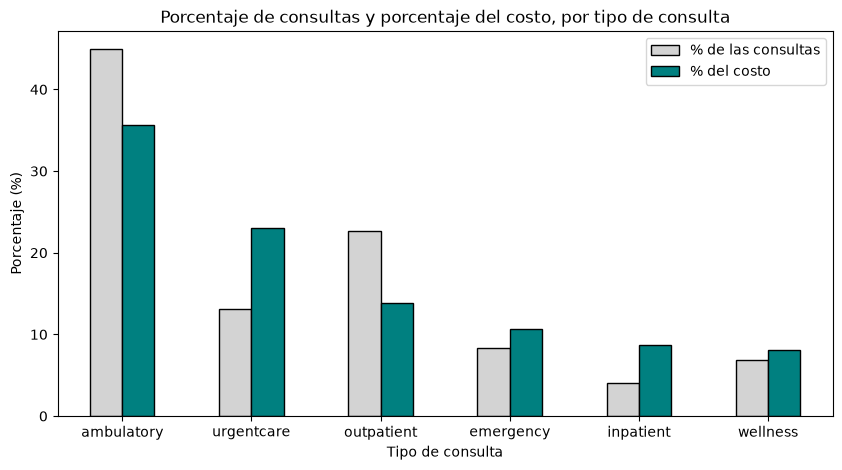

In [15]:
comparacion = costos_por_tipo.sort_values("%_costo", ascending=False)[["%_consultas", "%_costo"]]

comparacion.plot(kind="bar", figsize=(10, 5), color=["lightgray", "teal"], edgecolor="black")
plt.title("Porcentaje de consultas y porcentaje del costo, por tipo de consulta")
plt.xlabel("Tipo de consulta")
plt.ylabel("Porcentaje (%)")
plt.xticks(rotation=0)
plt.legend(["% de las consultas", "% del costo"])
plt.show()

### Qué encontramos: la hipótesis SE RECHAZA

Las internaciones **no** son las que más pesan en el presupuesto: pesan más las consultas ambulatorias y, sobre todo, las urgencias leves.

- Las **internaciones** son las consultas más caras de a una (**USD 7.761** en promedio), pero como son solo el **4,1%** de las consultas, representan apenas el **8,7% del costo**.
- Las **consultas ambulatorias** son las que más costo acumulan por su volumen: **44,9%** de las consultas y **35,7%** del costo.
- **Hallazgo clave:** las **urgencias leves** (*urgent care*: casos que necesitan atención rápida pero no son emergencias graves) son el **13,1%** de las consultas pero generan el **23% del costo**. Cuestan **USD 6.369** en promedio, más del doble que una consulta ambulatoria (USD 2.894).

## 7. H3: cobertura de los seguros

Si una parte grande de las consultas no tiene cobertura, el hospital depende de que los pacientes paguen de su bolsillo, y aumenta el riesgo de deudas que nunca se cobren.

A continuación contamos las consultas en las que el seguro no cubrió nada y calculamos qué porcentaje del costo total cubren los seguros y qué porcentaje pagan los pacientes.

In [16]:
sin_cobertura = encounters["PAYER_COVERAGE"] == 0

print("Consultas sin cobertura:", sin_cobertura.sum())
print("Porcentaje sin cobertura:", round(sin_cobertura.mean() * 100, 1), "%")

total_costo = encounters["TOTAL_CLAIM_COST"].sum()
total_cubierto = encounters["PAYER_COVERAGE"].sum()
print("Porcentaje del costo que cubren los seguros:", round(total_cubierto / total_costo * 100, 1), "%")
print("Porcentaje del costo que paga el paciente:", round((total_costo - total_cubierto) / total_costo * 100, 1), "%")

Consultas sin cobertura: 13586
Porcentaje sin cobertura: 48.7 %
Porcentaje del costo que cubren los seguros: 30.6 %
Porcentaje del costo que paga el paciente: 69.4 %


Para ver el detalle por aseguradora, unimos las consultas con la tabla de aseguradoras (un *merge*: juntar dos tablas usando una columna en común, en este caso el identificador de la aseguradora). Después de unir, verificamos que la cantidad de filas no haya cambiado: si aumentara, significaría que algunas consultas se duplicaron y los totales quedarían inflados.

A continuación hacemos la unión y comparamos la cantidad de filas antes y después.

In [17]:
consultas_con_seguro = encounters.merge(
    payers[["Id", "NAME"]],
    left_on="PAYER",
    right_on="Id",
    how="left",
    suffixes=("", "_payer")
)

print("Filas antes de unir:", encounters.shape)
print("Filas después de unir:", consultas_con_seguro.shape)
print("¿Se duplicaron filas?:", len(consultas_con_seguro) != len(encounters))

Filas antes de unir: (27891, 17)
Filas después de unir: (27891, 19)
¿Se duplicaron filas?: False


A continuación calculamos, para cada aseguradora, la cantidad de consultas, el costo total, el monto que cubrió y el porcentaje del costo que cubre.

In [18]:
por_aseguradora = consultas_con_seguro.groupby("NAME").agg(
    consultas=("Id", "count"),
    costo_total=("TOTAL_CLAIM_COST", "sum"),
    cubierto=("PAYER_COVERAGE", "sum")
).reset_index()

por_aseguradora["%_cubierto"] = round(por_aseguradora["cubierto"] / por_aseguradora["costo_total"] * 100, 1)

por_aseguradora.sort_values("consultas", ascending=False)

,NAME,consultas,costo_total,cubierto,%_cubierto
7,Medicare,11371,24647228.89,19215691.37,78.0
8,NO_INSURANCE,8807,49259290.16,0.00,0.0
6,Medicaid,1443,8954131.02,8417973.72,94.0
5,Humana,1084,3543921.36,1953.86,0.1
0,Aetna,936,2589956.10,1780.16,0.1
2,Blue Cross Blue Shield,925,3002166.01,2074496.34,69.1
4,Dual Eligible,912,1546925.99,1380705.87,89.3
9,UnitedHealthcare,900,2563507.98,3937.32,0.2
3,Cigna Health,809,2424532.96,968.35,0.0
1,Anthem,704,2982715.05,0.00,0.0


### Qué encontramos: la hipótesis SE CONFIRMA

Casi la mitad de las consultas no tiene cobertura, y la mayor parte del costo la pagan los pacientes: un **riesgo alto de cobranza**.

- **13.586 consultas (48,7%)** no tuvieron ninguna cobertura del seguro.
- Los seguros cubren solo el **30,6%** del costo total; los pacientes pagan el **69,4%**.
- Las **8.807 consultas de pacientes sin seguro** ("NO_INSURANCE") suman **USD 49,3 millones**, casi la mitad de la facturación del hospital.
- Los **programas públicos de salud** de Estados Unidos son los que más cubren:
  - **Medicaid** (para personas de bajos ingresos): 94%.
  - **Dual Eligible** (personas que tienen Medicare y Medicaid a la vez): 89,3%.
  - **Medicare** (para mayores de 65 años): 78%. Es la más usada, con **11.371 consultas**, en línea con la edad de los pacientes.
- Entre las privadas, **Blue Cross Blue Shield** cubre el 69,1%. Las demás (Humana, Aetna, UnitedHealthcare, Cigna y Anthem) cubren **menos del 1%**, lo que podría deberse al origen sintético de los datos.

## 8. H1: evolución en el tiempo

Ver cómo cambió la actividad año a año permite detectar picos y entender si el aumento de costos que percibe la dirección es real. Importante: **2022 está incompleto** (los datos llegan solo hasta febrero), así que no lo usamos para comparar.

A continuación calculamos, para cada año, la cantidad de consultas, los pacientes distintos atendidos, el costo total y el costo promedio por consulta.

In [19]:
por_año = encounters.groupby("AÑO").agg(
    consultas=("Id", "count"),
    pacientes=("PATIENT", "nunique"),
    costo_total=("TOTAL_CLAIM_COST", "sum"),
    costo_promedio=("TOTAL_CLAIM_COST", "mean")
).reset_index()

por_año

,AÑO,consultas,pacientes,costo_total,costo_promedio
0,2011,1336,410,4405936.73,3297.856834
1,2012,2106,559,9058314.10,4301.193780
2,2013,2495,570,10105272.87,4050.209567
3,2014,3885,630,12011662.17,3091.804934
4,2015,2469,553,10124652.89,4100.709959
5,2016,2451,552,8386701.12,3421.746683
6,2017,2360,546,9596894.47,4066.480708
7,2018,2292,535,8746818.37,3816.238381
8,2019,2228,514,8915338.78,4001.498555
9,2020,2519,519,10294077.96,4086.573227


A continuación graficamos la cantidad de consultas por año, dejando afuera 2022 por estar incompleto.

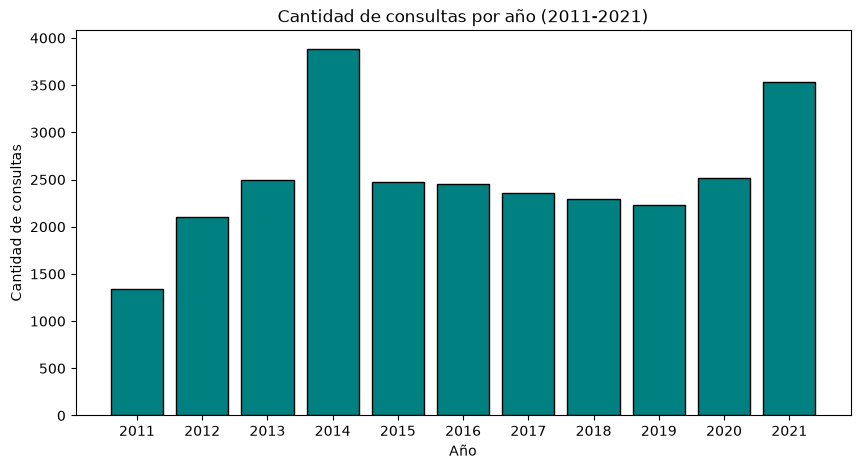

In [20]:
años_completos = por_año[por_año["AÑO"] < 2022]

plt.figure(figsize=(10, 5))
plt.bar(años_completos["AÑO"], años_completos["consultas"], color="teal", edgecolor="black")
plt.title("Cantidad de consultas por año (2011-2021)")
plt.xlabel("Año")
plt.ylabel("Cantidad de consultas")
plt.xticks(años_completos["AÑO"])
plt.show()

Se ven dos picos: 2014 y 2021. Para entender qué los causó, a continuación comparamos la cantidad de consultas por tipo en esos dos años contra 2016, que tomamos como un año normal. Es una *tabla cruzada*: cada fila es un año y cada columna un tipo de consulta.

In [21]:
años_a_comparar = encounters[encounters["AÑO"].isin([2016, 2014, 2021])]

años_a_comparar.groupby(["AÑO", "ENCOUNTERCLASS"]).size().unstack()

ENCOUNTERCLASS,ambulatory,emergency,inpatient,outpatient,urgentcare,wellness
AÑO,,,,,,
2014,2341,216,118,694,327,189
2016,1073,250,124,481,341,182
2021,1303,221,55,1418,378,155


En 2021 crecieron mucho las consultas externas. A continuación vemos cuáles fueron las 10 consultas más frecuentes de ese año.

In [22]:
encounters[encounters["AÑO"] == 2021]["DESCRIPTION"].value_counts().head(10)

DESCRIPTION
Administration of vaccine to produce active immunity (procedure)    1001
Encounter for problem (procedure)                                    494
Urgent care clinic (procedure)                                       375
Telemedicine consultation with patient                               338
Encounter for check up (procedure)                                   253
Emergency Encounter                                                  158
Encounter for symptom                                                151
General examination of patient (procedure)                           149
Follow-up encounter                                                  132
Encounter for 'check-up'                                              70
Name: count, dtype: int64

### Qué encontramos: la hipótesis SE CONFIRMA

La actividad del hospital no fue pareja: hubo **dos picos muy marcados**, por motivos distintos.

- **2014:** 3.885 consultas, un **59% más que un año normal** (unas 2.450). Se debe a que las **consultas ambulatorias se duplicaron** (2.341 contra 1.073 en 2016). Ese año también concentra la mayoría de las duraciones erróneas (sección 5), por lo que podría haber problemas de carga de datos.
- **2021:** 3.530 consultas. Las **consultas externas casi se triplicaron** (1.418 contra 481 en 2016) por la **aplicación de vacunas** (1.001 consultas, probablemente asociadas al COVID-19) y la **telemedicina** (338). Al mismo tiempo, las **internaciones cayeron un 56%** (55 contra 124).
- En ambos picos el **costo promedio bajó** (USD 3.092 en 2014 y USD 2.600 en 2021), porque las consultas adicionales fueron de bajo costo.
- **2022** se excluye de las comparaciones por estar incompleto (solo hasta febrero).

## 9. H4: reinternaciones

Que un paciente vuelva a internarse poco después de recibir el alta suele indicar que el problema de salud no se resolvió del todo, y genera costos que podrían evitarse. Usamos esta **regla de negocio**: una **reinternación** es una internación que empieza **dentro de los 30 días posteriores al alta** de una internación anterior del mismo paciente.

A continuación nos quedamos solo con las internaciones y las ordenamos por paciente y por fecha, para poder comparar cada internación con la anterior del mismo paciente.

In [23]:
internaciones = encounters[encounters["ENCOUNTERCLASS"] == "inpatient"].sort_values(["PATIENT", "START"]).copy()

print("Internaciones:", len(internaciones))

Internaciones: 1135


Para cada internación necesitamos la fecha de alta de la internación **anterior** del mismo paciente. Usamos `shift`, que "corre" la columna una fila hacia abajo dentro de cada paciente: así, en cada fila queda la fecha de alta de la fila anterior. Es lo mismo que hace la función `LAG` en SQL. La primera internación de cada paciente queda vacía, porque no tiene una anterior.

A continuación creamos la columna `ALTA_ANTERIOR`.

In [24]:
internaciones["ALTA_ANTERIOR"] = internaciones.groupby("PATIENT")["STOP"].shift(1)

internaciones[["PATIENT", "START", "STOP", "ALTA_ANTERIOR"]].head(10)

,PATIENT,START,STOP,ALTA_ANTERIOR
1403,002bc307-2fff-04ba-161b-98cce123e226,2012-01-19 19:30:33,2012-01-20 19:30:33,NaT
8398,002bc307-2fff-04ba-161b-98cce123e226,2014-06-19 19:30:33,2014-06-20 19:30:33,2012-01-20 19:30:33
2167,0034fe01-207f-275f-6b4b-821f7b0af044,2012-05-27 11:15:07,2012-05-28 11:15:07,NaT
4951,0034fe01-207f-275f-6b4b-821f7b0af044,2013-08-04 11:15:07,2013-08-05 11:15:07,2012-05-28 11:15:07
6042,0034fe01-207f-275f-6b4b-821f7b0af044,2014-01-19 11:15:07,2014-01-20 11:15:07,2013-08-05 11:15:07
22719,0034fe01-207f-275f-6b4b-821f7b0af044,2020-07-01 11:15:07,2020-07-02 11:15:07,2014-01-20 11:15:07
64,01274098-150f-8211-6150-29f2a2da266c,2011-01-23 14:53:31,2011-01-24 14:53:31,NaT
12188,01296e88-f6d9-1c18-cf91-87523325e034,2015-12-19 05:14:51,2015-12-20 05:14:51,NaT
5457,0226f105-2572-1c6f-15f0-1aa0438e40d0,2013-10-22 00:16:17,2013-11-14 00:16:17,NaT
5533,0226f105-2572-1c6f-15f0-1aa0438e40d0,2013-10-31 18:38:09,2013-11-01 18:38:09,2013-11-14 00:16:17


Ahora calculamos los **días desde el alta anterior** y marcamos como reinternación las internaciones que empiezan entre 0 y 30 días después. Si los días dan negativos, la internación empezó **antes** del alta de la anterior: la llamamos *internación superpuesta*.

A continuación calculamos los días, marcamos las reinternaciones y contamos las internaciones superpuestas.

In [25]:
internaciones["DIAS_DESDE_ALTA"] = (internaciones["START"] - internaciones["ALTA_ANTERIOR"]).dt.days
internaciones["REINTERNACION"] = internaciones["DIAS_DESDE_ALTA"].between(0, 30)

superpuestas = internaciones["DIAS_DESDE_ALTA"] < 0
print("Internaciones superpuestas:", superpuestas.sum())

internaciones[["PATIENT", "START", "ALTA_ANTERIOR", "DIAS_DESDE_ALTA", "REINTERNACION"]].head(10)

Internaciones superpuestas: 143


,PATIENT,START,ALTA_ANTERIOR,DIAS_DESDE_ALTA,REINTERNACION
1403,002bc307-2fff-04ba-161b-98cce123e226,2012-01-19 19:30:33,NaT,NaN,False
8398,002bc307-2fff-04ba-161b-98cce123e226,2014-06-19 19:30:33,2012-01-20 19:30:33,881.0,False
2167,0034fe01-207f-275f-6b4b-821f7b0af044,2012-05-27 11:15:07,NaT,NaN,False
4951,0034fe01-207f-275f-6b4b-821f7b0af044,2013-08-04 11:15:07,2012-05-28 11:15:07,433.0,False
6042,0034fe01-207f-275f-6b4b-821f7b0af044,2014-01-19 11:15:07,2013-08-05 11:15:07,167.0,False
22719,0034fe01-207f-275f-6b4b-821f7b0af044,2020-07-01 11:15:07,2014-01-20 11:15:07,2354.0,False
64,01274098-150f-8211-6150-29f2a2da266c,2011-01-23 14:53:31,NaT,NaN,False
12188,01296e88-f6d9-1c18-cf91-87523325e034,2015-12-19 05:14:51,NaT,NaN,False
5457,0226f105-2572-1c6f-15f0-1aa0438e40d0,2013-10-22 00:16:17,NaT,NaN,False
5533,0226f105-2572-1c6f-15f0-1aa0438e40d0,2013-10-31 18:38:09,2013-11-14 00:16:17,-14.0,False


A continuación calculamos la **tasa de reinternación** (qué porcentaje de las internaciones son reinternaciones) y cuántos pacientes se internaron y se reinternaron.

In [26]:
tasa = internaciones["REINTERNACION"].mean() * 100
pacientes_reinternados = internaciones.loc[internaciones["REINTERNACION"], "PATIENT"].nunique()

print("Reinternaciones:", internaciones["REINTERNACION"].sum())
print("Tasa de reinternación:", round(tasa, 1), "%")
print("Pacientes internados al menos una vez:", internaciones["PATIENT"].nunique())
print("Pacientes que se reinternaron al menos una vez:", pacientes_reinternados)

Reinternaciones: 458
Tasa de reinternación: 40.4 %
Pacientes internados al menos una vez: 153
Pacientes que se reinternaron al menos una vez: 29


Para saber si el problema está repartido o concentrado en pocos pacientes, a continuación armamos un ranking de pacientes según su cantidad de reinternaciones y mostramos los 10 primeros.

In [27]:
reinternaciones_por_paciente = (
    internaciones[internaciones["REINTERNACION"]]
    .groupby("PATIENT")
    .size()
    .sort_values(ascending=False)
)

reinternaciones_por_paciente.head(10)

PATIENT
a80b1160-93f0-db7e-9f23-04ea6fdddfaf    52
54889029-0a1e-0b75-5980-1c091dd4bc0e    49
12f0d3df-7ea9-3005-ea7e-a4c829536a12    38
40fd8032-aff7-ec24-bffa-66a09cb2c77d    35
0226f105-2572-1c6f-15f0-1aa0438e40d0    34
a96d5031-46d5-e3f6-ec67-81f8edd48aa8    34
905d0433-9ca3-4883-cbd4-3df36fd5f1c6    32
7412b008-76f9-b713-c514-2a5d82e3b39e    29
e7eaf3df-a981-d555-12d6-fdd50fa2631e    25
d30d80ca-f88c-bbdc-e56b-f32be78738c3    18
dtype: int64

A continuación calculamos qué porcentaje de todas las reinternaciones corresponde a esos 10 pacientes.

In [28]:
top_10 = reinternaciones_por_paciente.head(10).sum()
total = reinternaciones_por_paciente.sum()

print("Reinternaciones de los 10 primeros:", top_10)
print("Porcentaje del total:", round(top_10 / total * 100, 1), "%")

Reinternaciones de los 10 primeros: 346
Porcentaje del total: 75.5 %


### Qué encontramos: la hipótesis SE CONFIRMA

Las reinternaciones son frecuentes, pero **se concentran en muy pocos pacientes**.

- La **tasa de reinternación es del 40,4%**: 458 de las 1.135 internaciones ocurrieron dentro de los 30 días del alta anterior.
- De **153 pacientes internados**, solo **29 (19%)** se reinternaron.
- **10 pacientes explican el 75,5% de todas las reinternaciones**. Un solo paciente llegó a **52**.
- Además, hay **143 internaciones superpuestas** (empiezan antes del alta de la anterior): pueden ser errores de carga o traslados entre áreas del hospital.

Esto es una buena noticia para la gestión: **con un programa enfocado en pocos pacientes se puede atacar gran parte del problema**.

## 10. Conclusiones y recomendaciones

### Resultado de las hipótesis

| Hipótesis | Resultado | Lo más importante |
|---|---|---|
| **H1:** la actividad y los costos cambiaron mucho entre años | **SE CONFIRMA** | Dos picos: 2014 (+59% de consultas, por las ambulatorias) y 2021 (vacunas y telemedicina). En ambos bajó el costo promedio. |
| **H2:** las internaciones concentran la mayor parte de los costos | **SE RECHAZA** | Las internaciones son el 8,7% del costo. Las urgencias leves son el 13,1% de las consultas pero el 23% del costo. |
| **H3:** una parte grande de las consultas no tiene cobertura | **SE CONFIRMA** | El 48,7% de las consultas no tuvo cobertura y los pacientes pagan el 69,4% de los costos. |
| **H4:** algunos pacientes se reinternan con mucha frecuencia | **SE CONFIRMA** | Tasa de reinternación del 40,4%; 10 pacientes explican el 75,5% de las reinternaciones. |

### Problemas de calidad de los datos

- **17 consultas** no hospitalarias con duraciones imposibles (de hasta 5 años). Eran el 0,06% de los datos, pero inflaban la duración promedio de 2,1 a 7,3 horas. Las excluimos de ese cálculo.
- **143 internaciones superpuestas**: posibles errores de carga o traslados entre áreas.
- Los **códigos postales** se cargan como texto para no perder los ceros iniciales.
- Las **fechas** tenían zona horaria; las normalizamos para poder compararlas.
- No hay filas duplicadas en procedimientos ni en aseguradoras.
- Los **datos personales** de los pacientes (nombre y dirección) no se usan en el análisis.

### Recomendaciones

- **Revisar los costos de las urgencias leves** y evaluar derivar parte de esos casos a consultas ambulatorias programadas, que son más económicas.
- **Reducir el riesgo de cobranza:** ayudar a los pacientes sin seguro a inscribirse en programas públicos (muchos son mayores de 65 años y podrían acceder a Medicare) y ofrecer planes de pago.
- **Crear un programa de seguimiento después del alta** para el grupo reducido de pacientes que concentra las reinternaciones: con pocos recursos se puede atacar gran parte del problema.

### Consideraciones

- Los datos son sintéticos, por lo que algunas magnitudes (como la cobertura de las aseguradoras privadas o la tasa de reinternación) podrían no reflejar la realidad de un hospital.
- No hay pacientes menores de 26 años.
- 2022 está incompleto (solo hasta febrero) y se excluyó de las comparaciones entre años.